# Modelos de regresión - Viajes en taxi de Nueva York (enero 2015)

Se entrenaron y compararon modelos de regresión sobre el dataset limpio `yellow_tripdata_2015-01_clean.csv` para predecir la duración del viaje (`trip_duration_min`) a partir de la distancia recorrida, la hora de partida y las coordenadas de partida y llegada.

### Importar datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, ParameterGrid, train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

PATH = "../data/yellow_tripdata_2015-01_clean.csv"
CHUNK = 2_000_000
cols = {1: "tpep_pickup_datetime", 4: "trip_distance", 5: "pickup_longitude", 6: "pickup_latitude",
        9: "dropoff_longitude", 10: "dropoff_latitude", 19: "trip_duration_min"}

partes = []
for chunk in pd.read_csv(PATH, header=None, skiprows=1, usecols=list(cols), chunksize=CHUNK):
    chunk.columns = list(cols.values())
    pickup = pd.to_datetime(chunk.pop("tpep_pickup_datetime"), format="%Y-%m-%d %H:%M:%S")
    chunk.insert(1, "pickup_hour", pickup.dt.hour + pickup.dt.minute / 60)
    partes.append(chunk.astype(np.float32))
df = pd.concat(partes, ignore_index=True)
del partes

features = ["trip_distance", "pickup_hour", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]
X = df[features].to_numpy()
y = df["trip_duration_min"].to_numpy(np.float64)
del df

print(f"Filas: {len(X):,}")
print(f"Variables: {features}")

Filas: 12,402,772
Variables: ['trip_distance', 'pickup_hour', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']


### Pipeline

Todos los modelos son regresiones lineales sin regularización que difieren en la transformación aplicada a las variables:
- **Lineal**: variables originales.
- **Polinomial**: potencias y productos de las variables hasta grado `degree`.
- **Fourier**: variables originales más `sin(πkz)` y `cos(πkz)` de cada variable `z` normalizada a [0, 1], con k = 1, ..., `n_frecuencias`.

Las variables se estandarizan con la media y desviación del conjunto de entrenamiento antes de transformarse. Por memoria, los mínimos cuadrados se resuelven acumulando las ecuaciones normales por bloques. Para cada modelo se selecciona la configuración con menor RMSE medio de validación.

In [2]:
class Fourier(TransformerMixin, BaseEstimator):
    def __init__(self, n_frecuencias=1):
        self.n_frecuencias = n_frecuencias

    def fit(self, X, y=None):
        self.min_, self.rango_ = X.min(axis=0), np.ptp(X, axis=0)
        return self

    def transform(self, X):
        z = (X - self.min_) / self.rango_
        ang = (np.pi * z[:, :, None] * np.arange(1, self.n_frecuencias + 1)).reshape(len(X), -1)
        return np.hstack([X, np.sin(ang), np.cos(ang)])

class MinimosCuadrados(RegressorMixin, BaseEstimator):
    def __init__(self, transformacion=None, bloque=100_000):
        self.transformacion = transformacion
        self.bloque = bloque

    def _disenar(self, X):
        Z = self.escala_.transform(X.astype(np.float64))
        return Z if self.transformacion_ is None else self.transformacion_.transform(Z)

    def _bloques(self, X):
        return (slice(i, i + self.bloque) for i in range(0, len(X), self.bloque))

    def fit(self, X, y):
        self.escala_ = StandardScaler().fit(X)
        self.transformacion_ = None if self.transformacion is None else clone(self.transformacion).fit(
            self.escala_.transform(np.vstack([X.min(axis=0), X.max(axis=0), X[:self.bloque]]).astype(np.float64)))
        Z0 = self._disenar(X[:self.bloque])
        cz, cy = Z0.mean(axis=0), y[:self.bloque].mean()
        ZtZ, Zty, sz, sy = 0, 0, 0, 0
        for b in self._bloques(X):
            Z, yb = self._disenar(X[b]) - cz, y[b] - cy
            ZtZ, Zty, sz, sy = ZtZ + Z.T @ Z, Zty + Z.T @ yb, sz + Z.sum(axis=0), sy + yb.sum()
        n = len(X)
        mz, my = sz / n, sy / n
        cov = ZtZ / n - np.outer(mz, mz)
        d = np.sqrt(np.diag(cov))
        w = np.linalg.lstsq(cov / np.outer(d, d), (Zty / n - mz * my) / d, rcond=None)[0] / d
        self.coef_ = w
        self.intercept_ = cy + my - (cz + mz) @ w
        return self

    def predict(self, X):
        return np.concatenate([self._disenar(X[b]) @ self.coef_ + self.intercept_ for b in self._bloques(X)])

In [3]:
K = 5
N_CV = 2_000_000
METRICAS = ["MSE", "RMSE", "MAE", "R2"]

def particionar(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67)
    cv_idx = np.random.default_rng(67).choice(len(X_train), size=min(N_CV, len(X_train)), replace=False)
    folds = [(cv_idx[tr], cv_idx[va]) for tr, va in KFold(n_splits=K, shuffle=True, random_state=67).split(cv_idx)]
    print(f"Train + validación: {len(X_train):,}")
    print(f"Test: {len(X_test):,}")
    print(f"Muestra para validación cruzada: {len(cv_idx):,}")
    print(f"Tamaño por fold: {len(folds[0][1]):,}")
    return X_train, X_test, y_train, y_test, folds

def metricas(y, y_pred):
    mse = mean_squared_error(y, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, y_pred), "R2": r2_score(y, y_pred)}

def config(params):
    return ", ".join(f"{k.split('__')[-1]}={v:g}" for k, v in sorted(params.items())) or "-"

def construir(modelo, params):
    return clone(modelo).set_params(**params)

def resumen(res):
    return res.groupby(["modelo", "config"], sort=False)[METRICAS].mean()

def entrenar(modelos, X, y, folds):
    entrenados, params_de, res = {}, {}, []
    for nombre, (modelo, grid) in modelos.items():
        for params in ParameterGrid(grid):
            cfg = config(params)
            params_de[nombre, cfg] = params
            for k, (tr, _) in enumerate(folds):
                m = construir(modelo, params).fit(X[tr], y[tr])
                entrenados[nombre, cfg, k] = m
                res.append({"modelo": nombre, "config": cfg, "fold": k + 1, **metricas(y[tr], m.predict(X[tr]))})
    return entrenados, params_de, pd.DataFrame(res)

def validar(entrenados, X, y, folds):
    res = []
    for (nombre, cfg, k), m in entrenados.items():
        va = folds[k][1]
        res.append({"modelo": nombre, "config": cfg, "fold": k + 1, **metricas(y[va], m.predict(X[va]))})
    return pd.DataFrame(res)

def seleccionar(train_cv, val_cv):
    mejor = dict(val_cv.groupby(["modelo", "config"], sort=False)["RMSE"].mean().groupby(level="modelo", sort=False).idxmin().tolist())
    mejor_df = pd.DataFrame(mejor.items(), columns=["modelo", "config"])
    comparacion = pd.concat({
        "train": train_cv.merge(mejor_df).groupby("modelo", sort=False)[METRICAS].mean(),
        "val": val_cv.merge(mejor_df).groupby("modelo", sort=False)[METRICAS].mean(),
    }, axis=1)
    comparacion.insert(0, "config", mejor_df.set_index("modelo")["config"])
    return mejor, comparacion

def entrenar_final(modelos, mejor, params_de, X, y):
    return {n: construir(modelos[n][0], params_de[n, mejor[n]]).fit(X, y) for n in modelos}

def coeficientes(finales):
    coefs = pd.DataFrame({n: m.coef_ for n, m in finales.items() if len(m.coef_) == len(features)}, index=features)
    coefs.loc["intercepto"] = [finales[n].intercept_ for n in coefs.columns]
    return coefs

def evaluar(finales, X, y):
    y_pred = {n: m.predict(X) for n, m in finales.items()}
    return y_pred, pd.DataFrame({n: metricas(y, p) for n, p in y_pred.items()}).T

In [4]:
labels = {
    "trip_distance": "Distancia", "pickup_hour": "Hora de partida",
    "pickup_longitude": "Longitud partida", "pickup_latitude": "Latitud partida",
    "dropoff_longitude": "Longitud llegada", "dropoff_latitude": "Latitud llegada",
}

def rejilla(n, ancho, alto, cols=2):
    filas = -(-n // cols)
    fig, axes = plt.subplots(filas, min(n, cols), figsize=(ancho * min(n, cols), alto * filas), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:n]

def graficar_hiperparametros(modelos, val_cv):
    ajustables = [n for n, (_, grid) in modelos.items() if grid]
    fig, axes = rejilla(len(ajustables), 4.5, 3.4, cols=3)
    for ax, nombre in zip(axes, ajustables):
        grid = modelos[nombre][1]
        param, *otros = grid
        for fijos in ParameterGrid({k: grid[k] for k in otros}):
            cfgs = [config({param: v, **fijos}) for v in grid[param]]
            rmse = val_cv[val_cv["modelo"] == nombre].groupby("config")["RMSE"].mean().reindex(cfgs)
            ax.plot(grid[param], rmse, marker="o", label=config(fijos) if fijos else None)
        if max(grid[param]) / min(grid[param]) >= 10:
            ax.set_xscale("log")
        else:
            ax.set_xticks(grid[param])
        ax.set_xlabel(param.split("__")[-1])
        ax.set_ylabel("RMSE (min)")
        ax.set_title(nombre)
        if otros:
            ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    plt.suptitle("RMSE medio de validación según hiperparámetro")
    plt.tight_layout()
    plt.show()

def graficar_folds(val_cv, mejor):
    sel = val_cv.merge(pd.DataFrame(mejor.items(), columns=["modelo", "config"]))
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
    w = 0.8 / len(mejor)
    folds_x = np.arange(1, K + 1)
    for ax, m in zip(axes, ["RMSE", "MAE", "R2"]):
        for i, nombre in enumerate(mejor):
            ax.bar(folds_x - 0.4 + w * (i + 0.5), sel.loc[sel["modelo"] == nombre, m], w, label=nombre)
        ax.set_xticks(folds_x)
        ax.set_xlabel("Fold")
        ax.set_title(m)
        ax.grid(alpha=0.3)
    handles, leg_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, leg_labels, loc="lower center", ncol=len(mejor), fontsize=8)
    plt.suptitle("Métricas de validación por fold")
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

def graficar_coeficientes(coefs):
    fig, ax = plt.subplots(figsize=(6, 3.6))
    pos = np.arange(len(features))
    h = 0.8 / len(coefs.columns)
    for i, nombre in enumerate(coefs.columns):
        ax.barh(pos - 0.4 + h * (i + 0.5), coefs.loc[features, nombre], h, label=nombre)
    ax.set_yticks(pos)
    ax.set_yticklabels([labels[f] for f in features])
    ax.axvline(0, color="black", lw=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("Coeficiente (min por desviación estándar)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.title("Coeficientes de los modelos")
    plt.tight_layout()
    plt.show()

def graficar_test(y, y_pred, n=500_000):
    sample = np.random.default_rng(67).choice(len(y), size=min(n, len(y)), replace=False)
    y_s = y[sample]
    y_max = np.quantile(y_s, 0.99)
    res_s = {nombre: y_s - p[sample] for nombre, p in y_pred.items()}
    res_lim = max(np.quantile(np.abs(r), 0.99) for r in res_s.values())

    fig, axes = rejilla(len(y_pred), 4.5, 4.5)
    for ax, nombre in zip(axes, y_pred):
        ax.scatter(y_s, y_pred[nombre][sample], s=8, alpha=0.35, rasterized=True)
        ax.plot([0, y_max], [0, y_max], color="tab:red", lw=2, ls="--")
        ax.set_xlim(0, y_max)
        ax.set_ylim(0, y_max)
        ax.set_xlabel("Duración real (min)")
        ax.set_ylabel("Duración predicha (min)")
        ax.set_title(nombre)
        ax.grid(alpha=0.3)
    plt.suptitle("Valores reales vs predichos")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 3.6))
    bins = np.linspace(-res_lim, res_lim, 61)
    for nombre, r in res_s.items():
        ax.hist(r.clip(-res_lim, res_lim), bins=bins, histtype="step", lw=1.5, label=nombre)
    ax.set_xlabel("Residuo (min)")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.title("Distribución de los residuos")
    plt.tight_layout()
    plt.show()

    fig, axes = rejilla(len(y_pred), 4.5, 3.6)
    for ax, nombre in zip(axes, y_pred):
        p = y_pred[nombre][sample]
        ax.scatter(p, res_s[nombre], s=8, alpha=0.35, rasterized=True)
        ax.axhline(0, color="tab:red", lw=2, ls="--")
        ax.set_xlim(0, np.quantile(p, 0.99))
        ax.set_ylim(-res_lim, res_lim)
        ax.set_xlabel("Duración predicha (min)")
        ax.set_ylabel("Residuo (min)")
        ax.set_title(nombre)
        ax.grid(alpha=0.3)
    plt.suptitle("Residuos vs predicción")
    plt.tight_layout()
    plt.show()

### Partición de datos

Se reserva el 20% de los datos como conjunto de test. Del 80% restante se toma una muestra aleatoria de 2 M de viajes que se divide en K = 5 folds para validación cruzada (entrenamiento y validación).

In [5]:
modelos = {
    "Lineal": (MinimosCuadrados(), {}),
    "Polinomial": (MinimosCuadrados(PolynomialFeatures(include_bias=False)), {"transformacion__degree": [2, 3]}),
    "Fourier": (MinimosCuadrados(Fourier()), {"transformacion__n_frecuencias": [1, 2, 4]}),
}

X_train, X_test, y_train, y_test, folds = particionar(X, y)
del X, y

Train + validación: 9,922,217
Test: 2,480,555
Muestra para validación cruzada: 2,000,000
Tamaño por fold: 400,000


### Entrenamiento

Para cada modelo y configuración de hiperparámetros se entrena un modelo por fold con los K - 1 folds restantes.

In [6]:
entrenados, params_de, train_cv = entrenar(modelos, X_train, y_train, folds)
resumen(train_cv).round(4)

MSE    RMSE     MAE      R2
modelo     config                                          
Lineal     -                32.9656  5.7416  3.7790  0.6167
Polinomial degree=2         27.3434  5.2291  3.2806  0.6821
           degree=3         25.1758  5.0175  3.0864  0.7073
Fourier    n_frecuencias=1  27.5779  5.2515  3.2816  0.6793
           n_frecuencias=2  26.0344  5.1024  3.1402  0.6973
           n_frecuencias=4  25.3183  5.0317  3.1025  0.7056

### Validación

Cada modelo se evalúa sobre el fold que no se usó en su entrenamiento.

In [7]:
val_cv = validar(entrenados, X_train, y_train, folds)
resumen(val_cv).round(4)

MSE    RMSE     MAE      R2
modelo     config                                          
Lineal     -                32.9666  5.7415  3.7790  0.6167
Polinomial degree=2         27.3811  5.2325  3.2807  0.6817
           degree=3         25.7381  5.0724  3.0873  0.7007
Fourier    n_frecuencias=1  27.6947  5.2624  3.2817  0.6780
           n_frecuencias=2  26.0832  5.1070  3.1405  0.6967
           n_frecuencias=4  25.6595  5.0652  3.1038  0.7017

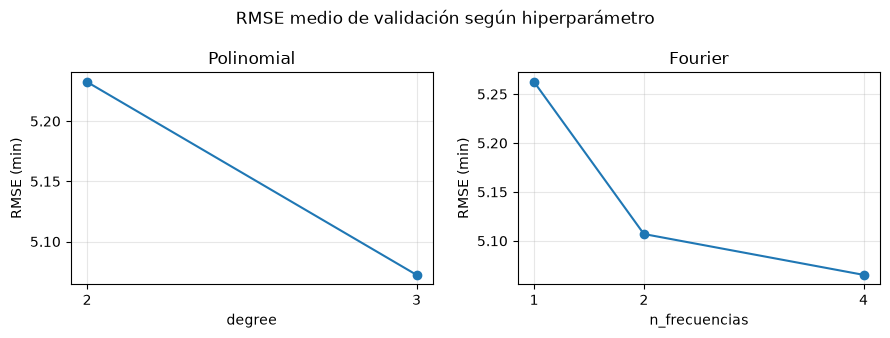

In [8]:
graficar_hiperparametros(modelos, val_cv)

In [9]:
mejor, comparacion = seleccionar(train_cv, val_cv)
comparacion.round(4)

config    train                              val          \
                                 MSE    RMSE     MAE      R2      MSE    RMSE   
modelo                                                                          
Lineal                    -  32.9656  5.7416  3.7790  0.6167  32.9666  5.7415   
Polinomial         degree=3  25.1758  5.0175  3.0864  0.7073  25.7381  5.0724   
Fourier     n_frecuencias=4  25.3183  5.0317  3.1025  0.7056  25.6595  5.0652   

                            
               MAE      R2  
modelo                      
Lineal      3.7790  0.6167  
Polinomial  3.0873  0.7007  
Fourier     3.1038  0.7017

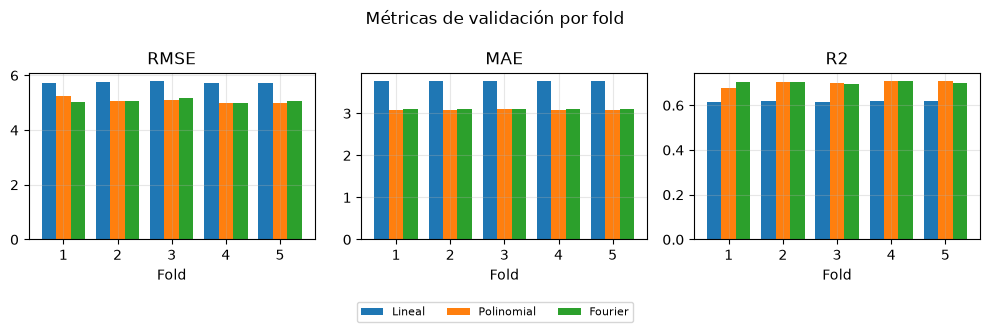

In [10]:
graficar_folds(val_cv, mejor)

### Modelo final

Cada modelo se reentrena con su mejor configuración sobre todo el conjunto de entrenamiento y validación.

In [11]:
finales = entrenar_final(modelos, mejor, params_de, X_train, y_train)
print("Número de variables por modelo:")
for nombre, m in finales.items():
    print(f"  {nombre}: {len(m.coef_)}")
coefs = coeficientes(finales)
coefs.round(4)

Número de variables por modelo:
  Lineal: 6
  Polinomial: 83
  Fourier: 54


,Lineal
trip_distance,7.9700
pickup_hour,0.1917
pickup_longitude,-0.8916
pickup_latitude,0.4208
dropoff_longitude,-0.4464
dropoff_latitude,-0.1864
intercepto,12.3577


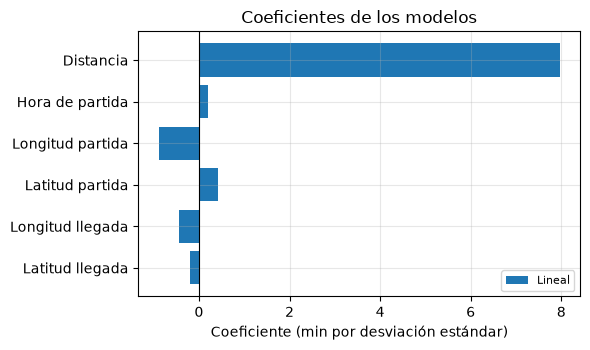

In [12]:
graficar_coeficientes(coefs)

### Evaluación en test

Los modelos finales se evalúan sobre el conjunto de test. Las gráficas se realizaron sobre una muestra aleatoria de 500 mil viajes del conjunto de test, recortando los ejes al percentil 99 únicamente para mejorar la visualización.

In [13]:
y_pred, test = evaluar(finales, X_test, y_test)
test.round(4)

,MSE,RMSE,MAE,R2
Lineal,33.5455,5.7918,3.7760,0.6134
Polinomial,25.8913,5.0883,3.0863,0.7016
Fourier,25.9841,5.0975,3.1020,0.7005


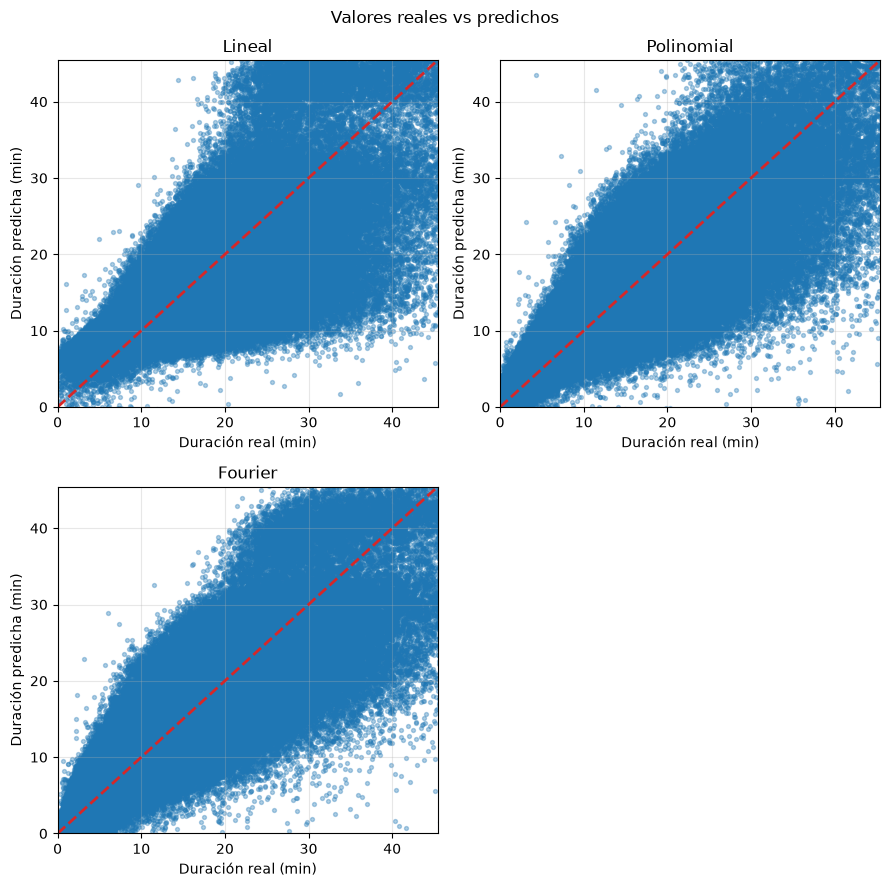

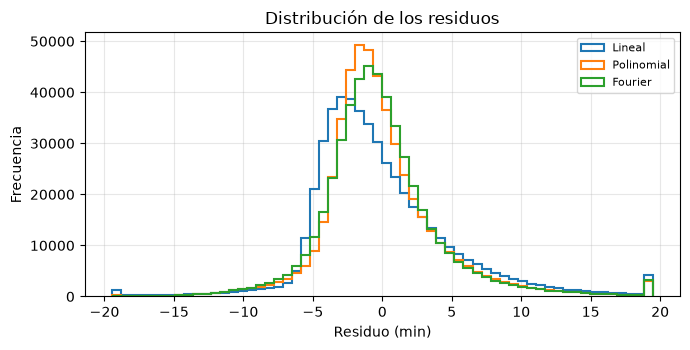

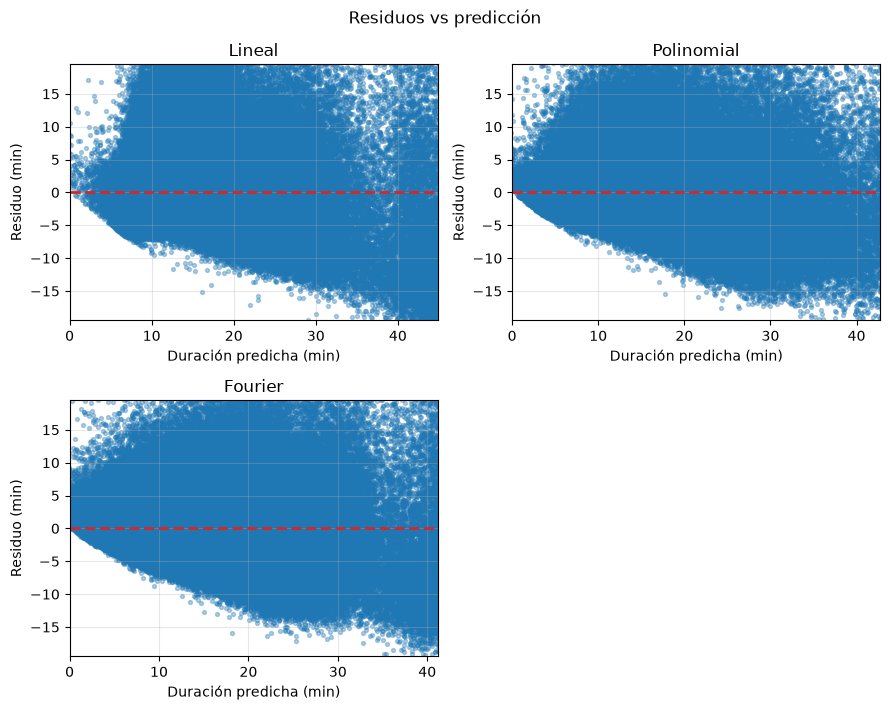

In [14]:
graficar_test(y_test, y_pred)